**Live Deployment Link:** https://PASTE-YOUR-LINK-HERE.streamlit.app/

---
# Household Energy Demand Forecasting System

## Setup: Running This Notebook From Scratch

### Option A: Google Colab (recommended, nothing to install)
1. Go to **https://colab.research.google.com** and sign in with a Google account.
2. Click **File -> Upload notebook** and choose this `.ipynb` file.
3. Click **Runtime -> Run all**.
4. When **Step 2.1** runs, a **"Choose Files"** button appears below that cell. Select **`household_power_consumption_csv.zip`** (19 MB, faster to upload) or **`household_power_consumption.csv`** (112 MB) from this project folder. The notebook continues automatically after the upload.

> **Note:** Colab deletes uploaded files when the runtime is reset. If you get a *"file not found"* error, run Step 2.1 again and re-upload the file.

The whole notebook takes about **3-6 minutes** on a free Colab runtime.

### Option B: Jupyter Notebook on your own computer
Follow these steps in a terminal, inside this project's folder, before opening the notebook.

#### 1. Check Python is installed
```
python --version
```
Python **3.11 or 3.12** is recommended (the pinned scikit-learn and NumPy versions need Python 3.11 or newer).

#### 2. Create a virtual environment
A virtual environment keeps this project's packages separate from the rest of your system.

**Windows (Command Prompt / PowerShell):**
```
python -m venv venv
```

**macOS / Linux:**
```
python3 -m venv venv
```

#### 3. Activate the virtual environment
You must do this every time you open a new terminal to work on this project.

**Windows (Command Prompt):**
```
venv\Scripts\activate.bat
```

**Windows (PowerShell):**
```
venv\Scripts\Activate.ps1
```
*(If PowerShell blocks this with an execution-policy error, run once: `Set-ExecutionPolicy -Scope CurrentUser RemoteSigned`)*

**macOS / Linux:**
```
source venv/bin/activate
```

Your terminal prompt should now show `(venv)` at the start of the line.

#### 4. Install the required packages
This project ships a `requirements.txt` file listing the exact package versions it was built and tested with.
```
pip install -r requirements.txt
pip install matplotlib tqdm prettytable notebook ipykernel
```
(The second command installs the extra packages the notebook uses for progress bars, tables and plots.)

#### 5. Register the virtual environment as a Jupyter kernel (recommended)
```
python -m ipykernel install --user --name=energy-venv --display-name "Python (energy-venv)"
```
When you open the notebook, make sure **Kernel -> Change Kernel -> Python (energy-venv)** is selected.

#### 6. Launch Jupyter Notebook
```
jupyter notebook
```
This opens Jupyter in your browser. Click this `.ipynb` file to open it, then run all cells from the top (**Kernel -> Restart & Run All**).

#### 7. When you're done
Deactivate the virtual environment with:
```
deactivate
```

---

## Notes on This Version
This notebook was adapted from the instructor's **Car Price Prediction - 10-Fold Cross Validation** notebook and follows the same approach (compare 5 regression algorithms with K-Fold Cross Validation and RMSE). What is different:
- **Problem & Dataset:** UCI *Individual Household Electric Power Consumption* (2,075,259 minute-level readings, Dec 2006 - Nov 2010). The task is to forecast the household's electricity use in the **next hour**.
- **Algorithms:** 5 algorithms that were **not used** in the Car Price system: **Ridge Regression, Extra Trees, AdaBoost, XGBoost, MLP Neural Network**.
- **Step 2.1** was added to show how `household_power_consumption.csv` is created from the raw UCI file `household_power_consumption.txt`.
- **Step 3.2** converts the minute-level data into hourly data, and **Step 4** creates time-series features (lags, daily/weekly memory, calendar).
- **Step 6.2** uses **un-shuffled folds** (`shuffle=False`), because the data is a time series. Shuffling would leak neighbouring hours into the training set.
- A **persistence baseline** ("next hour = this hour") is added so that the RMSE values can be judged.
- **Step 11** documents how the model was deployed as a public Streamlit web app.

## Description
<p>
A Household Energy Demand Forecasting System, a machine learning model that uses the recent electricity consumption, meter readings and time of day of a household to predict how much electricity it will use in the next hour. Five regression algorithms are compared with 10-fold cross validation on the full UCI Individual Household Electric Power Consumption dataset, and the best one is deployed as a web app.
</p>

## Introduction

##### **Definition** A regression ML task that predicts the average active power (kW) a household will use in the next hour (equal to the energy in kWh used in that hour).
##### **Application** Smart-home energy management, electricity demand forecasting for utility companies, scheduling appliances (washing machine, EV charging) in cheap off-peak hours, and detecting unusual consumption.

## Input and Output

### Inputs (Features / Attributes)

| **Input Feature/Attribute** | **Description** | **Type** | **Possible Values** |
| --- | --- | --- | --- |
| **power_now** | Average active power in the current hour | Numerical (kW) | 0.1 - 6.6 |
| **power_1h_ago** | Average active power 1 hour ago | Numerical (kW) | 0.1 - 6.6 |
| **power_2h_ago** | Average active power 2 hours ago | Numerical (kW) | 0.1 - 6.6 |
| **power_same_hour_yesterday** | Power in the forecast hour, one day earlier | Numerical (kW) | 0.1 - 6.6 |
| **power_same_hour_last_week** | Power in the forecast hour, one week earlier | Numerical (kW) | 0.1 - 6.6 |
| **avg_power_last_24h** | Average power over the last 24 hours | Numerical (kW) | 0.2 - 3.3 |
| **voltage_now** | Average voltage in the current hour | Numerical (V) | 225 - 252 |
| **reactive_power_now** | Average reactive power in the current hour | Numerical (kW) | 0 - 0.8 |
| **kitchen_Wh_now** | Sub-meter 1: dishwasher, oven, microwave | Numerical (Wh) | 0 - 3,000 |
| **laundry_Wh_now** | Sub-meter 2: washing machine, dryer, fridge, light | Numerical (Wh) | 0 - 3,000 |
| **heater_ac_Wh_now** | Sub-meter 3: water heater, air conditioner | Numerical (Wh) | 0 - 1,300 |
| **hour** | Hour of the day being predicted | Numerical | 0 - 23 |
| **day_of_week** | Day of the week being predicted | Numerical | 0 = Monday ... 6 = Sunday |
| **month** | Month being predicted | Numerical | 1 - 12 |
| **is_weekend** | Is the predicted hour on Saturday/Sunday? | Binary | 0, 1 |

### Output (Prediction)

| **Output Attribute** | **Description** | **Possible Values** |
| --- | --- | --- |
| **next_hour_power** | Average active power in the next hour (kW) = energy used in that hour (kWh) | 0.1 - 6.6 |

### Examples (Household Power Dataset, selected columns)

| Forecast Hour | power_now | power_1h_ago | power_same_hour_yesterday | voltage_now | kitchen_Wh_now | laundry_Wh_now | heater_ac_Wh_now | next_hour_power |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| Tue 15-Jan-2008, 08:00 | 2.42 | 1.18 | 2.60 | 237.8 | 0 | 0 | 1,041 | **2.23** |
| Sat 19-Jan-2008, 20:00 | 2.87 | 2.58 | 1.87 | 237.0 | 0 | 6 | 1,034 | **2.63** |
| Thu 10-Jul-2008, 04:00 | 0.27 | 0.27 | 0.26 | 240.3 | 0 | 13 | 90 | **0.57** |
| Thu 24-Dec-2009, 21:00 | 4.39 | 4.68 | 1.22 | 241.7 | 1,477 | 9 | 1,114 | **2.97** |
| Sun 02-May-2010, 13:00 | 3.56 | 1.61 | 0.51 | 237.6 | 0 | 1,758 | 1,119 | **3.53** |

## Developer & System Information

| | |
| --- | --- |
| **Developer Name** | Saad Faisal |
| **Registration No.** | FA24-BSE-104 |
| **Course** | AIC354 Machine Learning Fundamentals, COMSATS University Islamabad, Lahore Campus |
| **Instructor** | Dr. Rao Muhammad Adeel Nawab |
| **Program Name** | household\_power\_kfold\_full\_dataset\_10fold |
| **IDE** | Google Colab / Jupyter Notebook |
| **Programming Language** | Python 3 |
| **Libraries** | NumPy, Pandas, Pickle (built-in), scikit-learn, XGBoost, Matplotlib, tqdm, PrettyTable |
| **Dataset** | `household_power_consumption.csv`, UCI Individual Household Electric Power Consumption (2,075,259 instances): https://archive.ics.uci.edu/dataset/235 |
| **Date of Completion** | 25-Oct-2026 |
| **Live App** | https://PASTE-YOUR-LINK-HERE.streamlit.app/ |

## Table of Content
- [Step 1: Import Libraries](#step-1)
- [Step 2: Load Sample Data](#step-2)
  - [Step 2.1: (Optional) Re-create household_power_consumption.csv from the raw UCI file](#step-2-1)
  - [Step 2.2: Load the data](#step-2-2)
- [Step 3: Understand and Pre-process Sample Data](#step-3)
  - [Step 3.1: Understand Sample Data](#step-3-1)
  - [Step 3.2: Pre-process Sample Data (Minutes -> Hours)](#step-3-2)
  - [Step 3.3: Visualise Consumption Patterns](#step-3-3)
- [Step 4: Feature Extraction](#step-4)
  - [Step 4.1: Create the Input Features and the Output](#step-4-1)
  - [Step 4.2: Calculate a Simple Baseline](#step-4-2)
- [Step 5: Build the Pre-processing Pipeline](#step-5)
- [Step 6: Execute the Training and Testing Phase (10-Fold Cross Validation)](#step-6)
  - [Step 6.1: Define the 5 Regression Algorithms](#step-6-1)
  - [Step 6.2: Create the 10-Fold Splitter](#step-6-2)
  - [Step 6.3: Inspect the Folds](#step-6-3)
  - [Step 6.4: Run 10-Fold Cross Validation for All 5 Algorithms](#step-6-4)
- [Step 7: Evaluate and Compare the Algorithms](#step-7)
  - [Step 7.1: RMSE of Each Algorithm on Each Fold](#step-7-1)
  - [Step 7.2: Summary Comparison Table](#step-7-2)
  - [Step 7.3: Visual Comparison](#step-7-3)
  - [Step 7.4: Actual vs Predicted (One Unseen Week)](#step-7-4)
  - [Step 7.5: Observations](#step-7-5)
- [Step 8: Train and Save the Final Model](#step-8)
  - [Step 8.1: Select the Best Algorithm](#step-8-1)
  - [Step 8.2: Train the Best Algorithm on All the Data](#step-8-2)
  - [Step 8.3: Save the Trained Model](#step-8-3)
- [Step 9: Execute the Application Phase](#step-9)
  - [Step 9.1: Take Input from User](#step-9-1)
  - [Step 9.2: Convert User Input into Feature Vector](#step-9-2)
  - [Step 9.3: Load the Saved Model](#step-9-3)
  - [Step 9.4: Model Prediction](#step-9-4)
    - [Step 9.4.1: Apply Model and Return Prediction to the User](#step-9-4-1)
- [Step 10: Execute the Feedback Phase](#step-10)
  - [Step 10.1: Collect Feedback from Users and Domain Experts](#step-10-1)
  - [Step 10.2: Make a List of Potential Improvements](#step-10-2)
  - [Step 10.3: Improve the Model Based on Feedback](#step-10-3)
- [Step 11: Deploy Your Model as a Public Web App](#step-11)
  - [Step 11.1: Why Deploy a Model?](#step-11-1)
  - [Step 11.2: Create a GitHub Account and Repository](#step-11-2)
  - [Step 11.3: Write a Simple Web App](#step-11-3)
  - [Step 11.4: Create a Streamlit Community Cloud Account](#step-11-4)
  - [Step 11.5: Deploy Your App](#step-11-5)
  - [Step 11.6: Troubleshooting Common Issues](#step-11-6)
  - [Step 11.7: Share Your Live Link](#step-11-7)

## Code – Household Energy Demand Forecasting

<a id="step-1"></a>

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
Imports the libraries needed to download and load the data, build features,
run 10-fold cross validation for 5 regression algorithms, compare them,
save the best model, and show the results.
"""

# Built-in modules: files, timing, downloading and unzipping the dataset
import os
import time
import pickle
import zipfile
import urllib.request

# NumPy: numerical arrays and maths (e.g. square root for RMSE)
import numpy as np

# Pandas: DataFrames, reading the dataset, resampling minutes -> hours
import pandas as pd

# scikit-learn: cross validation, metrics and pre-processing
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# The 5 regression algorithms (none of them is used in the Car Price notebook)
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor, AdaBoostRegressor
from sklearn.neural_network import MLPRegressor
import xgboost
from xgboost import XGBRegressor

# Matplotlib: charts
import matplotlib
import matplotlib.pyplot as plt

# tqdm: progress bar with elapsed and remaining time
from tqdm import tqdm

# PrettyTable: prints the final prediction in a clean table
from prettytable import PrettyTable

# Show decimal numbers with 4 digits in pandas tables
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print("\n\nLibrary Versions Used in This Run:")
print("==================================\n")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"XGBoost      : {xgboost.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")



Library Versions Used in This Run:

NumPy        : 2.5.3
Pandas       : 3.0.5
scikit-learn : 1.9.1
XGBoost      : 3.4.1
Matplotlib   : 3.11.2


<a id="step-2"></a>

### Step 2: Load Sample Data

`household_power_consumption.csv` contains the **full** UCI *Individual Household Electric Power Consumption* dataset (https://archive.ics.uci.edu/dataset/235): **2,075,259** measurements of one house in Sceaux, France, recorded **every minute** from December 2006 to November 2010. A copy is included in this project folder (also as `household_power_consumption_csv.zip`, which is smaller to upload; pandas reads the ZIP directly).

The CSV was created from the raw UCI file `household_power_consumption.txt`: the separate `Date` and `Time` columns were combined into one `Datetime` column, the `;` separator was replaced with `,`, and missing values (written as `?` in the raw file) were left empty. The conversion script is in Step 2.1 below, so the process is reproducible.

<a id="step-2-1"></a>

#### Step 2.1: (Optional) Re-create household_power_consumption.csv from the raw UCI file

In [2]:
"""
Purpose of this section:
-------------------------
Makes sure the CSV dataset is available. This is optional: if
'household_power_consumption.csv' (or its ZIP) is already in the folder,
it is used directly. Otherwise:
1. In Google Colab, a 'Choose Files' button asks you to upload the CSV or ZIP.
2. If no CSV is available, the raw UCI file is downloaded and converted:
   - 'Date' + 'Time' are combined into one 'Datetime' column,
   - '?' (missing) becomes an empty value,
   - the result is saved as 'household_power_consumption.csv'.
"""

CSV_FILE = "household_power_consumption.csv"
CSV_ZIP_FILE = "household_power_consumption_csv.zip"
RAW_URLS = [
    "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip",
    "https://raw.githubusercontent.com/jbrownlee/Datasets/master/household_power_consumption.zip",  # mirror
]

# google.colab only exists inside Google Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def csv_available():
    return os.path.exists(CSV_FILE) or os.path.exists(CSV_ZIP_FILE)

# 1. Colab: upload the CSV (or its ZIP) from your computer
if not csv_available() and IN_COLAB:
    print(f"Please click 'Choose Files' and select '{CSV_FILE}' or '{CSV_ZIP_FILE}'")
    uploaded = files.upload()
    if uploaded:
        name = list(uploaded.keys())[0]
        os.rename(name, CSV_ZIP_FILE if name.endswith(".zip") else CSV_FILE)

# 2. Still no CSV: download the raw UCI file and convert it to CSV
if not csv_available():
    for url in RAW_URLS:
        try:
            print(f"Downloading raw UCI file from {url} ...")
            urllib.request.urlretrieve(url, "raw_uci.zip")
            break
        except Exception as error:
            print(f"  failed: {error}")
    with zipfile.ZipFile("raw_uci.zip") as z:
        txt_name = [n for n in z.namelist() if n.endswith(".txt")][0]
        with z.open(txt_name) as f:
            raw = pd.read_csv(f, sep=";", na_values="?", low_memory=False)
    raw.insert(0, "Datetime", raw["Date"] + " " + raw["Time"])
    raw["Datetime"] = pd.to_datetime(raw["Datetime"], format="%d/%m/%Y %H:%M:%S").dt.strftime("%Y-%m-%d %H:%M:%S")
    raw.drop(columns=["Date", "Time"]).to_csv(CSV_FILE, index=False)
    print(f"{CSV_FILE} re-created from the raw UCI file")

DATA_FILE = CSV_FILE if os.path.exists(CSV_FILE) else CSV_ZIP_FILE
print(f"Using '{DATA_FILE}' ({os.path.getsize(DATA_FILE) / 1e6:,.1f} MB)")

Using 'household_power_consumption.csv' (112.5 MB)


<a id="step-2-2"></a>

#### Step 2.2: Load the data

In [3]:
"""
Purpose of this section:
-------------------------
Loads ALL 2,075,259 rows of the CSV file into a pandas DataFrame and
displays the first rows so the raw data can be inspected.
- 'Datetime' is converted to a real date-time and used as the index.
- Empty cells (missing measurements) are read as NaN automatically.
"""

start = time.time()

# Read the CSV file (pandas can also read the .zip version directly)
power = pd.read_csv(DATA_FILE)

# Convert 'Datetime' text into real date-times and use it as the index
power["Datetime"] = pd.to_datetime(power["Datetime"], format="%Y-%m-%d %H:%M:%S")
power = power.set_index("Datetime").sort_index()

print(f"Loaded {len(power):,} rows in {time.time() - start:.1f} seconds")

print("\n\nSample Data (first 15 rows):")
print("============================\n")
print(power.head(15))

Loaded 2,075,259 rows in 4.0 seconds


Sample Data (first 15 rows):

                     Global_active_power  Global_reactive_power  Voltage  \
Datetime                                                                   
2006-12-16 17:24:00               4.2160                 0.4180 234.8400   
2006-12-16 17:25:00               5.3600                 0.4360 233.6300   
2006-12-16 17:26:00               5.3740                 0.4980 233.2900   
2006-12-16 17:27:00               5.3880                 0.5020 233.7400   
2006-12-16 17:28:00               3.6660                 0.5280 235.6800   
2006-12-16 17:29:00               3.5200                 0.5220 235.0200   
2006-12-16 17:30:00               3.7020                 0.5200 235.0900   
2006-12-16 17:31:00               3.7000                 0.5200 235.2200   
2006-12-16 17:32:00               3.6680                 0.5100 233.9900   
2006-12-16 17:33:00               3.6620                 0.5100 233.8600   
2006-12-16 17:34:00

<a id="step-3"></a>

### Step 3: Understand and Pre-process Sample Data

<a id="step-3-1"></a>

#### Step 3.1: Understand Sample Data

| Raw Attribute | Meaning |
| --- | --- |
| Global_active_power | Household average active power for that minute (kW), i.e. the power actually used |
| Global_reactive_power | Household average reactive power (kW) |
| Voltage | Average voltage (V) |
| Global_intensity | Average current (A) |
| Sub_metering_1 | Energy used by the **kitchen** (dishwasher, oven, microwave) in that minute (Wh) |
| Sub_metering_2 | Energy used by the **laundry room** (washing machine, dryer, fridge, a light) (Wh) |
| Sub_metering_3 | Energy used by the **electric water heater and air conditioner** (Wh) |

In [4]:
"""
Purpose of this section:
-------------------------
Helps us understand the dataset by showing:
1. The attribute (column) names.
2. The number of instances (rows) and the time period covered.
3. Missing values per column.
4. Summary statistics of every attribute.
"""

# 1. Attribute names
print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(list(power.columns))

# 2. Number of instances and time period
print("\n\nNumber of Instances in Sample Data:", f"{len(power):,}")
print("========================================\n")
print(f"Time period: {power.index.min()}  ->  {power.index.max()}")

# 3. Missing values
print("\nMissing values per column:")
missing = power.isnull().sum()
print(missing)
print(f"\nMissing minutes: {missing.max():,} ({missing.max() / len(power) * 100:.2f}% of all minutes)")

# 4. Summary statistics
print("\nSummary statistics:")
print(power.describe().T)



Attributes in Sample Data:

['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


Number of Instances in Sample Data: 2,075,259

Time period: 2006-12-16 17:24:00  ->  2010-11-26 21:02:00

Missing values per column:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Missing minutes: 25,979 (1.25% of all minutes)

Summary statistics:


                               count     mean    std      min      25%  \
Global_active_power   2,049,280.0000   1.0916 1.0573   0.0760   0.3080   
Global_reactive_power 2,049,280.0000   0.1237 0.1127   0.0000   0.0480   
Voltage               2,049,280.0000 240.8399 3.2400 223.2000 238.9900   
Global_intensity      2,049,280.0000   4.6278 4.4444   0.2000   1.4000   
Sub_metering_1        2,049,280.0000   1.1219 6.1530   0.0000   0.0000   
Sub_metering_2        2,049,280.0000   1.2985 5.8220   0.0000   0.0000   
Sub_metering_3        2,049,280.0000   6.4584 8.4372   0.0000   0.0000   

                           50%      75%      max  
Global_active_power     0.6020   1.5280  11.1220  
Global_reactive_power   0.1000   0.1940   1.3900  
Voltage               241.0100 242.8900 254.1500  
Global_intensity        2.6000   6.4000  48.4000  
Sub_metering_1          0.0000   0.0000  88.0000  
Sub_metering_2          0.0000   1.0000  80.0000  
Sub_metering_3          1.0000  17.0000  31.0000  

<a id="step-3-2"></a>

#### Step 3.2: Pre-process Sample Data (Minutes -> Hours)

| Step | What we do | Why |
| --- | --- | --- |
| 1 | Missing minutes are empty cells in the CSV, read as NaN in Step 2.2 | ~1.25% of minutes were not recorded (power cuts, meter failures) |
| 2 | **Resample to hourly averages** | Minute values are very noisy (a kettle switching on). Energy is planned **per hour**, and averaging ignores missing minutes automatically |
| 3 | Convert sub-meter values to **Wh per hour** | Average Wh per minute x 60 |
| 4 | Drop `Global_intensity` | Current (A) ≈ power / voltage, so it is almost a copy of the power and adds no new information |

All **2,075,259** measurements are used; they are summarised into about **34,600 hourly rows**.

In [5]:
"""
Purpose of this section:
-------------------------
Converts the minute-level data into hourly data (see the table above).
"""

# Average every column over each hour
hourly = power.resample("h").mean()

# Sub-meters: average Wh per minute x 60 = Wh used in the hour
for column in ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]:
    hourly[column] = hourly[column] * 60

# Global_intensity is almost a copy of Global_active_power, so we drop it
hourly = hourly.drop(columns=["Global_intensity"])

print("\n\nHourly Data (first 10 rows):")
print("============================\n")
print(hourly.head(10))
print(f"\nHourly rows                     : {len(hourly):,}")
print(f"Hours with no measurement at all: {hourly['Global_active_power'].isna().sum():,}")



Hourly Data (first 10 rows):

                     Global_active_power  Global_reactive_power  Voltage  \
Datetime                                                                   
2006-12-16 17:00:00               4.2229                 0.2290 234.6439   
2006-12-16 18:00:00               3.6322                 0.0800 234.5802   
2006-12-16 19:00:00               3.4002                 0.0852 233.2325   
2006-12-16 20:00:00               3.2686                 0.0751 234.0715   
2006-12-16 21:00:00               3.0565                 0.0767 237.1587   
2006-12-16 22:00:00               2.2001                 0.0562 238.7600   
2006-12-16 23:00:00               2.0616                 0.0714 240.6197   
2006-12-17 00:00:00               1.8825                 0.1024 240.9618   
2006-12-17 01:00:00               3.3494                 0.1369 240.4483   
2006-12-17 02:00:00               1.5873                 0.0782 245.8187   

                     Sub_metering_1  Sub_metering_2  Su

<a id="step-3-3"></a>

#### Step 3.3: Visualise Consumption Patterns

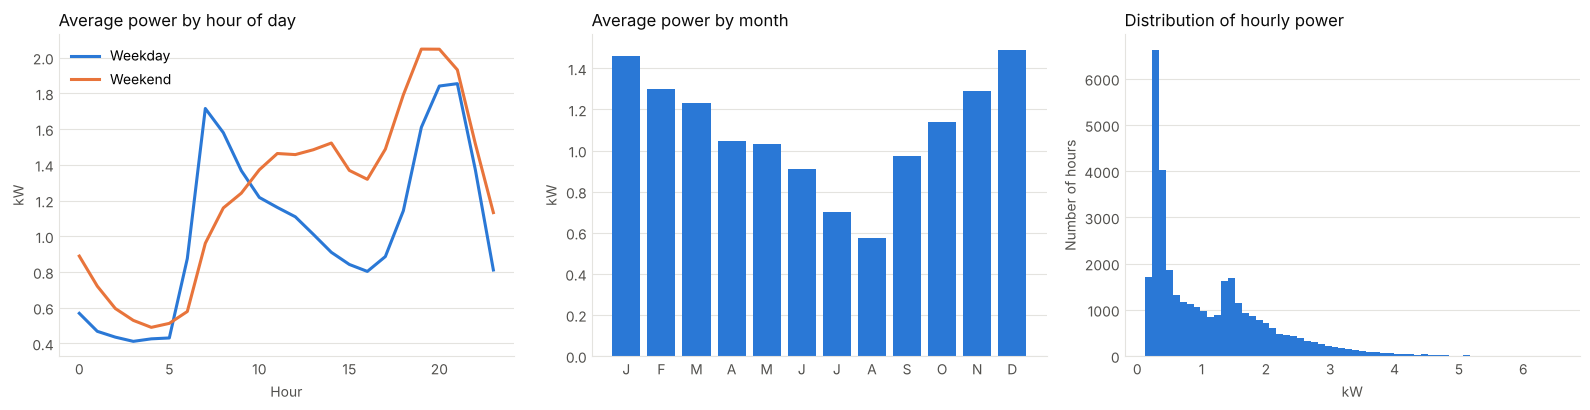

In [6]:
"""
Purpose of this section:
-------------------------
Plots three charts to check whether consumption follows patterns that an
algorithm could learn:
1. Average power by hour of day (weekdays vs weekends).
2. Average power by month.
3. Distribution (histogram) of hourly power.
"""

# Chart colours used throughout the notebook
BAR_COLOR, ACCENT = "#2a78d6", "#e8743b"
TEXT_COLOR, MUTED_TEXT, GRID_COLOR = "#0b0b0b", "#52514e", "#e4e3df"

def clean_axis(ax, grid_axis="y"):
    """Removes chart clutter: top/right borders, tick marks; adds a light grid."""
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID_COLOR)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.grid(axis=grid_axis, color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

ap = hourly["Global_active_power"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# 1) Average power by hour of day, weekdays vs weekends
weekend = ap.index.dayofweek >= 5
axes[0].plot(ap[~weekend].groupby(ap[~weekend].index.hour).mean(), color=BAR_COLOR, lw=2.2, label="Weekday")
axes[0].plot(ap[weekend].groupby(ap[weekend].index.hour).mean(), color=ACCENT, lw=2.2, label="Weekend")
axes[0].set_title("Average power by hour of day", loc="left", color=TEXT_COLOR)
axes[0].set_xlabel("Hour", color=MUTED_TEXT)
axes[0].set_ylabel("kW", color=MUTED_TEXT)
axes[0].legend(frameon=False)

# 2) Average power by month
monthly = ap.groupby(ap.index.month).mean()
axes[1].bar(monthly.index, monthly.values, color=BAR_COLOR)
axes[1].set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
axes[1].set_title("Average power by month", loc="left", color=TEXT_COLOR)
axes[1].set_ylabel("kW", color=MUTED_TEXT)

# 3) Distribution of hourly power
axes[2].hist(ap.dropna(), bins=60, color=BAR_COLOR)
axes[2].set_title("Distribution of hourly power", loc="left", color=TEXT_COLOR)
axes[2].set_xlabel("kW", color=MUTED_TEXT)
axes[2].set_ylabel("Number of hours", color=MUTED_TEXT)

for ax in axes:
    clean_axis(ax)
plt.tight_layout()
plt.show()

**What the charts tell us**
1. **Strong daily routine:** consumption is lowest at night (≈ 0.4 kW) and peaks in the evening (≈ 2 kW at 20:00-21:00). On weekdays there is a sharp 7:00 breakfast peak and a dip in the afternoon (people are at work); at weekends usage stays high from late morning through the afternoon (people are at home).
2. **Strong seasonal pattern:** winter months use about **twice** as much as summer (heating, lighting), and August is the lowest (summer holidays).
3. **Skewed output:** most hours use under 1.5 kW, but some reach 5-6 kW. RMSE squares errors, so these rare high-usage hours have a big influence on the RMSE.

These patterns are **non-linear**, which suggests that tree ensembles and neural networks should beat a linear model.

<a id="step-4"></a>

### Step 4: Feature Extraction

The goal is: **at the end of hour *t*, predict the average power in hour *t+1***. A model may only use information that is **already known at time *t***.

| Group | Features | Idea |
| --- | --- | --- |
| **Recent history (lags)** | power now, 1 h ago, 2 h ago | Consumption changes gradually |
| **Daily / weekly memory** | same hour yesterday, same hour last week | People repeat their routines |
| **Trend** | average of the last 24 hours | Captures cold days, holidays, guests |
| **Current readings** | voltage, reactive power, 3 sub-meters | *Which* appliances are running right now |
| **Calendar** | hour, day of week, month, is_weekend (of the hour being predicted) | Daily, weekly and seasonal pattern |

<a id="step-4-1"></a>

#### Step 4.1: Create the Input Features and the Output

In [7]:
"""
Purpose of this section:
-------------------------
Creates the 15 input features and the output (power in the NEXT hour),
then separates the input (X) from the output (y).
- shift(k) moves a column k hours down, i.e. gives the value from k hours ago.
- shift(-1) gives the value from the NEXT hour (the output we predict).
"""

p = hourly["Global_active_power"]
features = pd.DataFrame(index=hourly.index)

# Recent history
features["power_now"] = p
features["power_1h_ago"] = p.shift(1)
features["power_2h_ago"] = p.shift(2)

# Daily / weekly memory (relative to the hour being predicted, t+1)
features["power_same_hour_yesterday"] = p.shift(23)
features["power_same_hour_last_week"] = p.shift(167)

# Trend: average of the last 24 hours (needs at least 18 known hours)
features["avg_power_last_24h"] = p.rolling(24, min_periods=18).mean()

# Current meter readings
features["voltage_now"] = hourly["Voltage"]
features["reactive_power_now"] = hourly["Global_reactive_power"]
features["kitchen_Wh_now"] = hourly["Sub_metering_1"]
features["laundry_Wh_now"] = hourly["Sub_metering_2"]
features["heater_ac_Wh_now"] = hourly["Sub_metering_3"]

# Calendar of the hour being predicted
next_hour = features.index + pd.Timedelta(hours=1)
features["hour"] = next_hour.hour
features["day_of_week"] = next_hour.dayofweek
features["month"] = next_hour.month
features["is_weekend"] = (next_hour.dayofweek >= 5).astype(int)

# Output: power in the NEXT hour
features["next_hour_power"] = p.shift(-1)

# Keep only rows where the output and the current power are known
data = features.dropna(subset=["next_hour_power", "power_now"])

# Separate input (X) and output (y)
feature_names = [c for c in data.columns if c != "next_hour_power"]
target = "next_hour_power"
X = data[feature_names]
y = data[target]

print("\n\nFeature Vectors (first 10 rows):")
print("================================\n")
print(X.head(10))
print(f"\nInput features (X): {X.shape[1]} columns")
print(f"Output (y)        : {target}")
print(f"Number of hours   : {len(X):,}")
print(f"Missing input values (filled later by the pipeline): {X.isna().sum().sum():,}")



Feature Vectors (first 10 rows):

                     power_now  power_1h_ago  power_2h_ago  \
Datetime                                                     
2006-12-16 17:00:00     4.2229           NaN           NaN   
2006-12-16 18:00:00     3.6322        4.2229           NaN   
2006-12-16 19:00:00     3.4002        3.6322        4.2229   
2006-12-16 20:00:00     3.2686        3.4002        3.6322   
2006-12-16 21:00:00     3.0565        3.2686        3.4002   
2006-12-16 22:00:00     2.2001        3.0565        3.2686   
2006-12-16 23:00:00     2.0616        2.2001        3.0565   
2006-12-17 00:00:00     1.8825        2.0616        2.2001   
2006-12-17 01:00:00     3.3494        1.8825        2.0616   
2006-12-17 02:00:00     1.5873        3.3494        1.8825   

                     power_same_hour_yesterday  power_same_hour_last_week  \
Datetime                                                                    
2006-12-16 17:00:00                        NaN                   

<a id="step-4-2"></a>

#### Step 4.2: Calculate a Simple Baseline

In [8]:
"""
Purpose of this section:
-------------------------
A useful ML model must beat the simplest possible forecast:
"next hour will be the same as this hour" (a persistence forecast).
Its RMSE is used later as a reference line.
"""

baseline_rmse = np.sqrt(mean_squared_error(y, X["power_now"]))

print("\n\nPersistence Baseline:")
print("=====================\n")
print(f"Average hourly power      : {y.mean():.3f} kW")
print(f"Persistence baseline RMSE : {baseline_rmse:.4f} kW")



Persistence Baseline:

Average hourly power      : 1.092 kW
Persistence baseline RMSE : 0.6795 kW


<a id="step-5"></a>

### Step 5: Build the Pre-processing Pipeline

All inputs are numeric, so no label encoding is needed. The pipeline has two steps:

| Step | Why |
| --- | --- |
| **Fill missing values** with the median | A few lag features are missing (e.g. *last week* during a meter outage); algorithms cannot handle empty values |
| **Standard scaling** (mean 0, std 1) | Ridge and the **neural network** are sensitive to scale: *voltage* (~240) would otherwise dominate *power* (~1) |

Both steps are **inside** the pipeline, so in every cross-validation round they are fitted on the **training folds only**. This avoids data leakage.

In [9]:
"""
Purpose of this section:
-------------------------
Creates the pre-processing pipeline (median imputer -> standard scaler).
It is combined with each algorithm in Step 6.4.
"""

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # fill missing values
    ("scaler", StandardScaler()),                     # mean 0, std 1
])

print("\n\nPre-processing Pipeline:")
print("========================\n")
print(preprocessor)



Pre-processing Pipeline:

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


<a id="step-6"></a>

### Step 6: Execute the Training and Testing Phase (10-Fold Cross Validation)

**K-Fold Cross Validation** splits the data into **K = 10 folds**. In each of the 10 rounds, the model is **trained on 9 folds** and **tested on the remaining fold**, so every hour is used for testing exactly once. We report the **average RMSE** over the 10 rounds.

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

RMSE is in **kW** (same unit as the output). **Lower RMSE = better model.**

<a id="step-6-1"></a>

#### Step 6.1: Define the 5 Regression Algorithms

| # | Algorithm | How it predicts the next hour's consumption |
| --- | --- | --- |
| 1 | **Ridge Regression** | A linear (weighted-sum) model with an **L2 penalty** that keeps weights small; stable when features are correlated |
| 2 | **Extra Trees** | 100 trees whose split **thresholds are chosen randomly**; predictions are averaged |
| 3 | **AdaBoost** | Small trees trained one after another; badly predicted hours get a **higher weight** in the next tree |
| 4 | **XGBoost** | Optimised gradient-boosted trees with **built-in regularisation** and row/column sub-sampling |
| 5 | **MLP Neural Network** | Feed-forward neural network with two hidden layers (64 and 32 neurons) and early stopping |

In [10]:
"""
Purpose of this section:
-------------------------
Creates the 5 regression algorithms. Settings are kept close to the
defaults so the comparison is fair. random_state=42 makes results
reproducible. n_jobs=-1 uses all CPU cores.
"""

algorithms = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostRegressor(n_estimators=50, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6,
                            subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
    "MLP Neural Network": MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                                       max_iter=300, random_state=42),
}

print("\n\nAlgorithms to Compare:")
print("======================\n")
for number, name in enumerate(algorithms, start=1):
    print(f"{number}. {name}")



Algorithms to Compare:

1. Ridge Regression
2. Extra Trees
3. AdaBoost
4. XGBoost
5. MLP Neural Network


<a id="step-6-2"></a>

#### Step 6.2: Create the 10-Fold Splitter

Unlike the Car Price notebook (`shuffle=True`), this split uses **`shuffle=False`**. The data is a **time series**: hour 10:00 and hour 11:00 are almost identical. If we shuffled, the hour *just before* and *just after* every test hour would be in the training set and the model would look unrealistically good (**data leakage**). With `shuffle=False` each fold is a **continuous block of about 4.7 months**. The same folds are used for all 5 algorithms.

In [11]:
"""
Purpose of this section:
-------------------------
Creates the 10-fold splitter and stores the 10 (train, test) index pairs.
"""

K = 10
kfold = KFold(n_splits=K, shuffle=False)   # continuous time blocks
folds = list(kfold.split(X))

print(f"{K}-Fold Cross Validation created (shuffle=False, continuous time blocks)")

10-Fold Cross Validation created (shuffle=False, continuous time blocks)


<a id="step-6-3"></a>

#### Step 6.3: Inspect the Folds

In [12]:
"""
Purpose of this section:
-------------------------
Shows how many hours are used for training and testing in each round,
the time period of each test fold, and its average and maximum power.
"""

fold_info = []
for fold_number, (train_index, test_index) in enumerate(folds, start=1):
    test_period = X.index[test_index]
    fold_info.append({
        "Fold": fold_number,
        "Training Hours": len(train_index),
        "Testing Hours": len(test_index),
        "Test Period": f"{test_period.min():%b %Y} - {test_period.max():%b %Y}",
        "Avg Power in Test (kW)": y.iloc[test_index].mean(),
        "Max Power in Test (kW)": y.iloc[test_index].max(),
    })

print("\n\nTraining and Testing Hours in Each Fold:")
print("========================================\n")
print(pd.DataFrame(fold_info).set_index("Fold"))



Training and Testing Hours in Each Fold:

      Training Hours  Testing Hours          Test Period  \
Fold                                                       
1              30743           3416  Dec 2006 - May 2007   
2              30743           3416  May 2007 - Sep 2007   
3              30743           3416  Sep 2007 - Feb 2008   
4              30743           3416  Feb 2008 - Jul 2008   
5              30743           3416  Jul 2008 - Nov 2008   
6              30743           3416  Nov 2008 - Apr 2009   
7              30743           3416  Apr 2009 - Sep 2009   
8              30743           3416  Sep 2009 - Feb 2010   
9              30743           3416  Feb 2010 - Jun 2010   
10             30744           3415  Jun 2010 - Nov 2010   

      Avg Power in Test (kW)  Max Power in Test (kW)  
Fold                                                  
1                     1.3422                  6.3639  
2                     0.8302                  5.7358  
3              

<a id="step-6-4"></a>

#### Step 6.4: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing -> algorithm**). For each of the 10 folds we (1) make a **fresh copy** of the pipeline, (2) **train** it on the 9 training folds, (3) **predict** the test fold, and (4) calculate the **RMSE** and **R²**.

The `tqdm` progress bar has **5 x 10 = 50 steps** and shows the elapsed and **remaining time**. This step takes about 2-4 minutes in Colab.

In [13]:
"""
Purpose of this section:
-------------------------
Trains and tests every algorithm on every fold and stores the results.
"""

fold_rmse = {}              # RMSE on each fold, for each algorithm
fold_r2 = {}                # R² on each fold, for each algorithm
training_time = {}          # total time for all 10 folds
last_fold_predictions = {}  # predictions on fold 10 (used in Step 7.4)

with tqdm(total=len(algorithms) * K, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():

        # Pipeline = pre-processing + algorithm
        model = Pipeline([("preprocessor", preprocessor), ("regressor", algorithm)])

        rmses, r2s = [], []
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                   # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])    # train on 9 folds
            predictions = fold_model.predict(X.iloc[test_index])        # test on 1 fold

            rmses.append(np.sqrt(mean_squared_error(y.iloc[test_index], predictions)))
            r2s.append(r2_score(y.iloc[test_index], predictions))
            if fold_number == K:
                last_fold_predictions[name] = predictions
            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(rmses)
        fold_r2[name] = np.array(r2s)
        tqdm.write(f"{name:<20} -> mean RMSE = {fold_rmse[name].mean():.4f} kW   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

  0%|          | 0/50 [00:00<?, ?fold/s]

Ridge Regression, fold 1/10:   0%|          | 0/50 [00:00<?, ?fold/s]

Ridge Regression, fold 2/10:   2%|▏         | 1/50 [00:00<00:02, 17.88fold/s]

Ridge Regression, fold 2/10:   4%|▍         | 2/50 [00:00<00:02, 18.00fold/s]

Ridge Regression, fold 3/10:   4%|▍         | 2/50 [00:00<00:02, 18.00fold/s]

...

MLP Neural Network, fold 10/10: 100%|██████████| 50/50 [01:44<00:00,  3.94s/fold]

MLP Neural Network, fold 10/10: 100%|██████████| 50/50 [01:44<00:00,  3.94s/fold]

Done: 100%|██████████| 50/50 [01:44<00:00,  3.94s/fold]                          

Done: 100%|██████████| 50/50 [01:44<00:00,  2.10s/fold]

MLP Neural Network   -> mean RMSE = 0.5396 kW   (38.8 s)

10-fold cross validation completed for all 5 algorithms.


<a id="step-7"></a>

### Step 7: Evaluate and Compare the Algorithms

<a id="step-7-1"></a>

#### Step 7.1: RMSE of Each Algorithm on Each Fold

In [14]:
"""
Purpose of this section:
-------------------------
Shows the RMSE of every algorithm on every fold. The lowest RMSE in each
row (the best algorithm on that fold) is highlighted in green.
"""

per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

print("\n\nNumber of Folds Won by Each Algorithm:")
print("======================================\n")
print(per_fold_table.idxmin(axis=1).value_counts().to_string())

(per_fold_table.style
    .format("{:.4f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))



Number of Folds Won by Each Algorithm:

XGBoost    10


,Ridge Regression,Extra Trees,AdaBoost,XGBoost,MLP Neural Network
Fold,,,,,
Fold 1,0.6718,0.6255,0.9116,0.6044,0.6309
Fold 2,0.5656,0.5248,0.9694,0.5139,0.5450
Fold 3,0.6863,0.6299,0.8821,0.6127,0.6447
Fold 4,0.6045,0.5477,0.9249,0.5237,0.5660
Fold 5,0.5274,0.4737,0.9442,0.4504,0.4732
Fold 6,0.6252,0.5605,0.8699,0.5385,0.5817
Fold 7,0.4628,0.4144,0.9027,0.4029,0.4253
Fold 8,0.6033,0.5314,0.8643,0.5137,0.5580
Fold 9,0.5335,0.4764,0.8737,0.4662,0.4972


<a id="step-7-2"></a>

#### Step 7.2: Summary Comparison Table

| Column | Meaning |
| --- | --- |
| **Mean RMSE** | Average RMSE over the 10 folds, the **main measure for ranking** (lower is better) |
| **Std RMSE** | Standard deviation over the folds; small = consistent |
| **Best / Worst Fold** | Lowest and highest fold RMSE |
| **Mean R²** | Share of the variation explained (1.0 = perfect) |
| **Improvement over Baseline** | How much lower the RMSE is than the persistence baseline |
| **Time** | Total time to train and test across all 10 folds |

In [15]:
"""
Purpose of this section:
-------------------------
Summarises the 10-fold results of each algorithm in one table and ranks
the algorithms by mean RMSE (Rank 1 = best).
"""

summary = pd.DataFrame({
    "Mean RMSE (kW)": per_fold_table.mean(),
    "Std RMSE (kW)": per_fold_table.std(),
    "Best Fold RMSE (kW)": per_fold_table.min(),
    "Worst Fold RMSE (kW)": per_fold_table.max(),
    "Mean R²": pd.DataFrame(fold_r2).mean(),
    "Improvement over Baseline": (1 - per_fold_table.mean() / baseline_rmse) * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE (kW)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average next-hour power: {y.mean():.3f} kW   |   Persistence baseline RMSE: {baseline_rmse:.4f} kW\n")
(summary.style
    .format({"Mean RMSE (kW)": "{:.4f}", "Std RMSE (kW)": "{:.4f}", "Best Fold RMSE (kW)": "{:.4f}",
             "Worst Fold RMSE (kW)": "{:.4f}", "Mean R²": "{:.3f}",
             "Improvement over Baseline": "{:+.1f}%", "Time (s)": "{:.1f}"})
    .highlight_min(subset=["Mean RMSE (kW)"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average next-hour power: 1.092 kW   |   Persistence baseline RMSE: 0.6795 kW



,Rank,Mean RMSE (kW),Std RMSE (kW),Best Fold RMSE (kW),Worst Fold RMSE (kW),Mean R²,Improvement over Baseline,Time (s)
Algorithm,,,,,,,,
XGBoost,1,0.5065,0.0687,0.4029,0.6127,0.649,+25.5%,8.1
Extra Trees,2,0.5225,0.0724,0.4144,0.6299,0.627,+23.1%,27.9
MLP Neural Network,3,0.5396,0.0713,0.4253,0.6447,0.601,+20.6%,38.8
Ridge Regression,4,0.5779,0.0733,0.4628,0.6863,0.543,+14.9%,0.5
AdaBoost,5,0.9008,0.0364,0.8643,0.9694,-0.184,-32.6%,29.5


<a id="step-7-3"></a>

#### Step 7.3: Visual Comparison

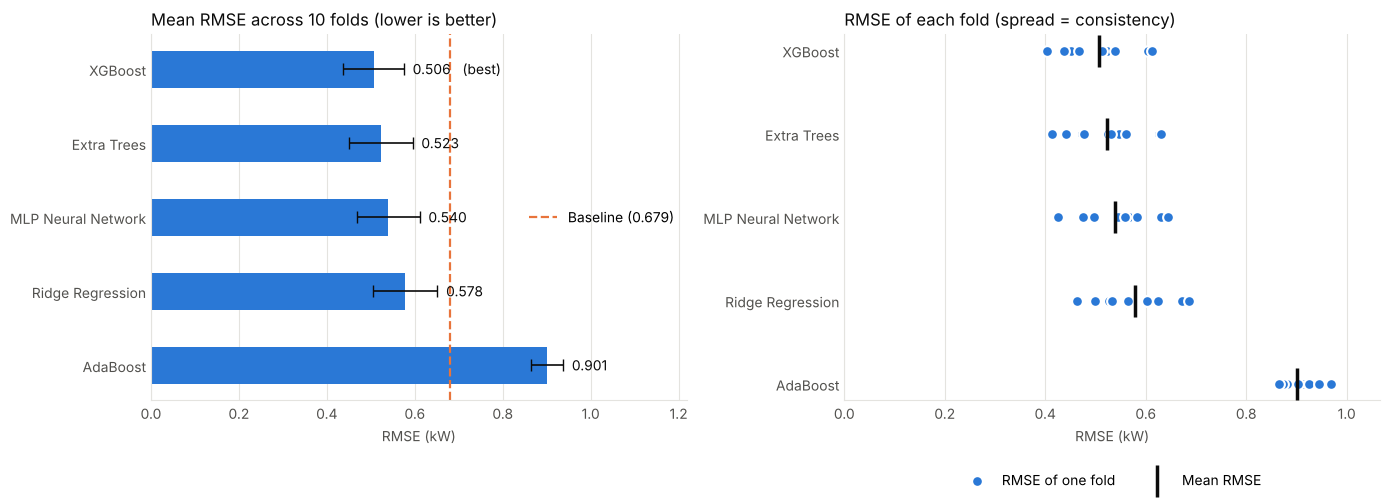

In [16]:
"""
Purpose of this section:
-------------------------
Chart 1: mean RMSE of each algorithm (+/- 1 standard deviation); the dashed
         line is the persistence baseline.
Chart 2: RMSE of every individual fold as a dot (spread = consistency).
"""

order = summary.index.tolist()          # best algorithm first
positions = np.arange(len(order))
means = summary["Mean RMSE (kW)"]
stds = summary["Std RMSE (kW)"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# ---- Chart 1: mean RMSE with +/- 1 std ----
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
ax1.axvline(baseline_rmse, color=ACCENT, ls="--", lw=1.6, label=f"Baseline ({baseline_rmse:.3f})")
for i, name in enumerate(order):
    label = f"{means[name]:.3f}" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + 0.02, i, label, va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, max((means + stds).max(), baseline_rmse) * 1.3)
clean_axis(ax1, grid_axis="x")
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (kW)", color=MUTED_TEXT)
ax1.legend(frameon=False, loc="center right")

# ---- Chart 2: RMSE of every fold ----
for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR, edgecolor="white",
                linewidth=1.5, zorder=3, label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(means[name], i, marker="|", s=500, color=TEXT_COLOR, linewidth=2.5, zorder=4,
                label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
ax2.set_xlim(0, per_fold_table.values.max() * 1.1)
clean_axis(ax2, grid_axis="x")
ax2.set_title("RMSE of each fold (spread = consistency)", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (kW)", color=MUTED_TEXT)
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)

plt.tight_layout()
plt.show()

<a id="step-7-4"></a>

#### Step 7.4: Actual vs Predicted (One Unseen Week)

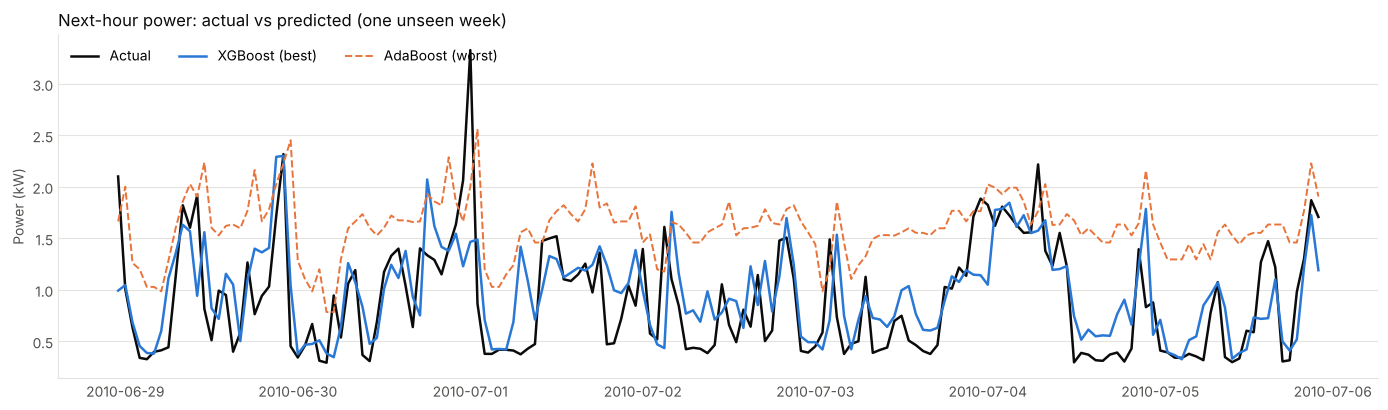

In [17]:
"""
Purpose of this section:
-------------------------
Plots one week of real consumption from the last test fold against the
predictions of the best and the worst algorithm (hours they never saw
during training), to show what the RMSE values mean in practice.
"""

best_name, worst_name = order[0], order[-1]
test_index = folds[-1][1]
week = slice(0, 24 * 7)                                  # first 168 hours
times = X.index[test_index][week] + pd.Timedelta(hours=1)

fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(times, y.iloc[test_index].values[week], color=TEXT_COLOR, lw=1.8, label="Actual")
ax.plot(times, last_fold_predictions[best_name][week], color=BAR_COLOR, lw=1.8, label=f"{best_name} (best)")
ax.plot(times, last_fold_predictions[worst_name][week], color=ACCENT, lw=1.4, ls="--", label=f"{worst_name} (worst)")
clean_axis(ax)
ax.set_ylabel("Power (kW)", color=MUTED_TEXT)
ax.set_title("Next-hour power: actual vs predicted (one unseen week)", loc="left", color=TEXT_COLOR, fontsize=12)
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

<a id="step-7-5"></a>

#### Step 7.5: Observations

> The numbers below come from our run. If your library versions are different, your numbers may differ slightly, but the overall pattern should be the same.

1. **XGBoost has the lowest mean RMSE (≈ 0.506 kW)** and **wins all 10 folds**, followed by **Extra Trees (≈ 0.523 kW)** and the **MLP Neural Network (≈ 0.540 kW)**. The gaps are small compared with the fold-to-fold standard deviation (≈ 0.07 kW), but because XGBoost is ahead on *every* fold, its lead is consistent, not luck, and it is also one of the fastest.
2. **Non-linear models win.** Ridge Regression (≈ 0.578 kW) is clearly behind the top three, because the effect of the hour, season and appliance usage on consumption is **not linear**.
3. **Four of the five algorithms beat the persistence baseline** (≈ 0.679 kW); XGBoost reduces the error by about **25%**, so the models really learn the household's routine.
4. **AdaBoost performs worst (≈ 0.90 kW), even worse than the baseline.** The week plot shows why: its predictions are **systematically too high** (about 0.5-1 kW above the actual curve at night). AdaBoost keeps increasing the weight of the hours it predicts badly, which here are the rare high-consumption hours, so with default settings (50 small trees of depth 3) the ensemble is pulled upwards for ordinary hours.
5. **Winter folds are the hardest.** Folds 1, 3, 6 and 8 (which contain December-February) have the highest RMSE (XGBoost ≈ 0.51-0.61 kW), while the summer folds 7 and 10 have the lowest (≈ 0.40-0.44 kW).
6. **Remaining error is natural randomness:** nobody can predict exactly when a person will switch on the oven or the washing machine, so even the best model misses sudden spikes.

<a id="step-8"></a>

### Step 8: Train and Save the Final Model

<a id="step-8-1"></a>

#### Step 8.1: Select the Best Algorithm

In [18]:
"""
Purpose of this section:
-------------------------
Cross validation is used to CHOOSE an algorithm, not to produce the final
model. We pick the algorithm with the lowest mean RMSE (Rank 1).
"""

best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE (kW)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE (kW)"]

print("\n\nBest Algorithm:")
print("===============\n")
print(f"Algorithm     : {best_algorithm_name}")
print(f"Expected RMSE : {best_mean_rmse:.4f} kW (+/- {best_std_rmse:.4f} kW)")



Best Algorithm:

Algorithm     : XGBoost
Expected RMSE : 0.5065 kW (+/- 0.0687 kW)


<a id="step-8-2"></a>

#### Step 8.2: Train the Best Algorithm on All the Data

In [19]:
"""
Purpose of this section:
-------------------------
Trains the best algorithm on ALL the hours. No separate test set is needed:
the cross-validation RMSE from Step 7 is our estimate of its performance.
"""

final_model = Pipeline([("preprocessor", preprocessor),
                        ("regressor", clone(algorithms[best_algorithm_name]))])
final_model.fit(X, y)

print(f"Final {best_algorithm_name} model trained on {len(X):,} hours")

Final XGBoost model trained on 34,159 hours


<a id="step-8-3"></a>

#### Step 8.3: Save the Trained Model

In [20]:
"""
Purpose of this section:
-------------------------
Saves the trained pipeline (imputer + scaler + algorithm) together with the
information the web app needs (feature order, CV results) to a .pkl file.
Also writes requirements.txt with the EXACT library versions of this run;
the web app must use the same versions, otherwise the .pkl may not load.
Set DOWNLOAD_FILES = True in Colab to download both files.
"""

MODEL_FILE = "household_power_model.pkl"
DOWNLOAD_FILES = False

model_package = {
    "model": final_model,
    "algorithm": best_algorithm_name,
    "feature_names": feature_names,
    "cv_rmse_mean": float(best_mean_rmse),
    "cv_rmse_std": float(best_std_rmse),
    "baseline_rmse": float(baseline_rmse),
    "feature_medians": X.median().to_dict(),
    "cv_summary": summary[["Rank", "Mean RMSE (kW)", "Std RMSE (kW)", "Mean R²"]].reset_index().to_dict("records"),
}

# 'wb' = write in binary mode
pickle.dump(model_package, open(MODEL_FILE, "wb"))
print(f"Saved: {MODEL_FILE} ({os.path.getsize(MODEL_FILE) / 1e6:.2f} MB)")

# requirements.txt for the web app (same versions as this run)
requirements = f"""streamlit
numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
"""
with open("requirements.txt", "w") as f:
    f.write(requirements)
print("Saved: requirements.txt\n")
print(requirements)

if IN_COLAB and DOWNLOAD_FILES:
    files.download(MODEL_FILE)
    files.download("requirements.txt")

Saved: household_power_model.pkl (1.41 MB)
Saved: requirements.txt

streamlit
numpy==2.5.3
pandas==3.0.5
scikit-learn==1.9.1
xgboost==3.4.1



<a id="step-9"></a>

### Step 9: Execute the Application Phase

<a id="step-9-1"></a>

#### Step 9.1: Take Input from User

A demo hour (a winter weekday evening) is pre-filled so the notebook runs top-to-bottom. To enter your own values interactively, replace the demo values with `input()` lines, for example:
```python
power_now = float(input("Average power in the current hour (kW): "))
hour = int(input("Hour being predicted (0-23): "))
```

In [21]:
"""
Purpose of this section:
-------------------------
Takes the readings of the CURRENT hour for a new (unseen) case.
Edit the values below to try your own.
"""

# Demo hour: Wednesday in January, predicting 20:00-21:00
power_now = 2.10                    # kW
power_1h_ago = 1.60                 # kW
power_2h_ago = 1.20                 # kW
power_same_hour_yesterday = 2.40    # kW
power_same_hour_last_week = 2.20    # kW
avg_power_last_24h = 1.30           # kW
voltage_now = 239.5                 # V
reactive_power_now = 0.12           # kW
kitchen_Wh_now = 0                  # Wh
laundry_Wh_now = 30                 # Wh
heater_ac_Wh_now = 600              # Wh
hour = 20                           # hour being predicted (0-23)
day_of_week = 2                     # 0 = Monday ... 6 = Sunday
month = 1                           # 1-12

print(f"Power now: {power_now} kW, 1h ago: {power_1h_ago} kW, 2h ago: {power_2h_ago} kW")
print(f"Same hour yesterday: {power_same_hour_yesterday} kW, last week: {power_same_hour_last_week} kW, "
      f"24h average: {avg_power_last_24h} kW")
print(f"Voltage: {voltage_now} V, Reactive power: {reactive_power_now} kW")
print(f"Kitchen: {kitchen_Wh_now} Wh, Laundry: {laundry_Wh_now} Wh, Heater/AC: {heater_ac_Wh_now} Wh")
print(f"Forecast hour: {hour}:00, Day of week: {day_of_week}, Month: {month}")

Power now: 2.1 kW, 1h ago: 1.6 kW, 2h ago: 1.2 kW
Same hour yesterday: 2.4 kW, last week: 2.2 kW, 24h average: 1.3 kW
Voltage: 239.5 V, Reactive power: 0.12 kW
Kitchen: 0 Wh, Laundry: 30 Wh, Heater/AC: 600 Wh
Forecast hour: 20:00, Day of week: 2, Month: 1


<a id="step-9-2"></a>

#### Step 9.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [22]:
"""
Purpose of this section:
-------------------------
Puts the user's input into a one-row DataFrame with exactly the same
columns, in the same order, as the training data. No manual scaling is
needed: the saved pipeline does it automatically.
"""

user_input = pd.DataFrame([{
    "power_now": power_now,
    "power_1h_ago": power_1h_ago,
    "power_2h_ago": power_2h_ago,
    "power_same_hour_yesterday": power_same_hour_yesterday,
    "power_same_hour_last_week": power_same_hour_last_week,
    "avg_power_last_24h": avg_power_last_24h,
    "voltage_now": voltage_now,
    "reactive_power_now": reactive_power_now,
    "kitchen_Wh_now": kitchen_Wh_now,
    "laundry_Wh_now": laundry_Wh_now,
    "heater_ac_Wh_now": heater_ac_Wh_now,
    "hour": hour,
    "day_of_week": day_of_week,
    "month": month,
    "is_weekend": int(day_of_week >= 5),
}])[feature_names]

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input.T.rename(columns={0: "value"}))



User Input Feature Vector:

                             value
power_now                   2.1000
power_1h_ago                1.6000
power_2h_ago                1.2000
power_same_hour_yesterday   2.4000
power_same_hour_last_week   2.2000
avg_power_last_24h          1.3000
voltage_now               239.5000
reactive_power_now          0.1200
kitchen_Wh_now              0.0000
laundry_Wh_now             30.0000
heater_ac_Wh_now          600.0000
hour                       20.0000
day_of_week                 2.0000
month                       1.0000
is_weekend                  0.0000


<a id="step-9-3"></a>

#### Step 9.3: Load the Saved Model

In [23]:
"""
Purpose of this section:
-------------------------
Loads the saved model again for the Application Phase.
"""

# 'rb' = read in binary mode
loaded = pickle.load(open(MODEL_FILE, "rb"))
model = loaded["model"]
print(f"Model loaded from {MODEL_FILE}: {loaded['algorithm']}")

Model loaded from household_power_model.pkl: XGBoost


<a id="step-9-4"></a>

#### Step 9.4: Model Prediction

<a id="step-9-4-1"></a>

#### Step 9.4.1: Apply Model on the Feature Vector of unseen instance and return Prediction to the User

In [24]:
"""
Purpose of this section:
-------------------------
Predicts the household's average power for the next hour and shows the
result to the user, together with the typical error of the model.
"""

# Model returns an array, e.g. [2.19]; [0] picks the single value
predicted_power = model.predict(user_input)[0]
rmse = loaded["cv_rmse_mean"]

# Display the prediction in a table
pretty_table = PrettyTable()
pretty_table.field_names = ["** Forecast Hour **", "** Predicted Power **", "** Likely Range **"]
pretty_table.add_row([f"{hour:02d}:00 - {(hour + 1) % 24:02d}:00",
                      f"{predicted_power:.3f} kW (≈ {predicted_power:.3f} kWh)",
                      f"{max(predicted_power - rmse, 0):.2f} - {predicted_power + rmse:.2f} kW"])
print(pretty_table)

+---------------------+------------------------+--------------------+
| ** Forecast Hour ** | ** Predicted Power **  | ** Likely Range ** |
+---------------------+------------------------+--------------------+
|    20:00 - 21:00    | 2.195 kW (≈ 2.195 kWh) |   1.69 - 2.70 kW   |
+---------------------+------------------------+--------------------+


<a id="step-10"></a>

### Step 10: Execute the Feedback Phase

<a id="step-10-1"></a>

#### Step 10.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [25]:
"""
Purpose of this section:
-------------------------
Step 10.1: Example feedback from domain experts and users who reviewed
the model's forecasts.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Energy Utility)", "Household User", "Domain Expert (Energy Utility)"],
    "Case": [
        "Winter weekday evening, water heater on -> predicted about 2.2 kW",
        "Sunday afternoon, washing machine started -> forecast was lower than the real use",
        "Model uses one household and no weather data",
    ],
    "Feedback": [
        "Realistic: evening peaks with electric water heating are typical in French homes.",
        "Sudden appliance switch-ons are missed; the forecast catches up one hour later.",
        "Temperature and holidays strongly affect demand; the model should not be used for other homes as-is.",
    ],
})
print(example_feedback.to_string(index=False))

                      Reviewer                                                                              Case                                                                                             Feedback
Domain Expert (Energy Utility)                 Winter weekday evening, water heater on -> predicted about 2.2 kW                    Realistic: evening peaks with electric water heating are typical in French homes.
                Household User Sunday afternoon, washing machine started -> forecast was lower than the real use                      Sudden appliance switch-ons are missed; the forecast catches up one hour later.
Domain Expert (Energy Utility)                                      Model uses one household and no weather data Temperature and holidays strongly affect demand; the model should not be used for other homes as-is.


<a id="step-10-2"></a>

#### Step 10.2: Make a List of Potential Improvements

In [26]:
"""
Purpose of this section:
-------------------------
Step 10.2: Improvements identified from the feedback above.
"""

improvements = [
    "Add weather data (outside temperature, sunlight), because heating and lighting depend on it",
    "Add public and school holiday information (note the August dip)",
    "Tune hyper-parameters of XGBoost and the MLP with RandomizedSearchCV and TimeSeriesSplit",
    "Forecast the next 24 hours instead of only the next hour",
    "Train on data from many households so the model generalises to new homes",
]

# Print as a numbered list
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Add weather data (outside temperature, sunlight), because heating and lighting depend on it
2. Add public and school holiday information (note the August dip)
3. Tune hyper-parameters of XGBoost and the MLP with RandomizedSearchCV and TimeSeriesSplit
4. Forecast the next 24 hours instead of only the next hour
5. Train on data from many households so the model generalises to new homes


<a id="step-10-3"></a>

#### Step 10.3: Improve the Model Based on Feedback

In [27]:
"""
Purpose of this section:
-------------------------
Step 10.3: In a real deployment the next version would add the improvements
above, re-run Steps 6-7, and replace the deployed model only if the
cross-validation RMSE improves.
"""

print("Next version: add temperature and holiday features, tune XGBoost, then re-run Steps 6-7 "
      f"and replace {MODEL_FILE} only if the mean RMSE drops below {best_mean_rmse:.3f} kW.")

Next version: add temperature and holiday features, tune XGBoost, then re-run Steps 6-7 and replace household_power_model.pkl only if the mean RMSE drops below 0.506 kW.


<a id="step-11"></a>

## Step 11: Deploy Your Model as a Public Web App

So far, running this notebook only lets *you* use the model, and only while Colab/Jupyter is open. This section shows how the model was turned into a **live website** anyone can open in a browser, with nothing to install. Live app for this project: https://PASTE-YOUR-LINK-HERE.streamlit.app/

<a id="step-11-1"></a>

#### Step 11.1: Why Deploy a Model?

A trained model is only useful if people other than you can access it. Deploying it as a small web app is how data scientists share results with non-technical users (households, energy companies, teachers) who won't run a notebook themselves.

<a id="step-11-2"></a>

#### Step 11.2: Create a GitHub Account and Repository

1. If you don't have one, sign up for a free account at **https://github.com**.
2. Create a new repository (click the **+** icon top-right -> **New repository**). Give it a name (e.g. `household-energy-forecast`), keep it **Public**, and click **Create repository**.
3. Upload this project's files (**Add file -> Upload files**). You need `app.py`, `requirements.txt` and the trained model file `household_power_model.pkl` (see Step 11.3).

<a id="step-11-3"></a>

#### Step 11.3: Write a Simple Web App

The file `app.py` in this project folder is a small **Streamlit** script that turns the model into a web form. It:
1. Loads `household_power_model.pkl` with `pickle.load(...)` (the pipeline already contains the imputer and scaler, so no manual pre-processing is needed).
2. Uses Streamlit widgets (`st.date_input`, `st.slider`, `st.number_input`) to collect the date/hour, recent consumption and current meter readings.
3. Builds the feature vector in exactly the same column order as `feature_names`.
4. Calls `model.predict(...)` on a button click and shows the forecast and its likely range with `st.success(...)`.

A `requirements.txt` in the **same folder** as `app.py` lists the packages the app needs. It is written automatically in Step 8.3, with the same versions used to train the model:
```
streamlit
numpy==<version from Step 8.3>
pandas==<version from Step 8.3>
scikit-learn==<version from Step 8.3>
xgboost==<version from Step 8.3>
```

<a id="step-11-4"></a>

#### Step 11.4: Create a Streamlit Community Cloud Account

1. Go to **https://share.streamlit.io**.
2. Click **Sign in with GitHub** and authorise Streamlit to access your repositories. This is free for public apps.

<a id="step-11-5"></a>

#### Step 11.5: Deploy Your App

1. On the Streamlit Cloud dashboard, click **Create app** -> **Deploy a public app from GitHub**.
2. Fill in: **Repository** `<your-username>/household-energy-forecast`, **Branch** `main`, **Main file path** `app.py`.
3. Open **Advanced settings** and choose **Python 3.12**.
4. Click **Deploy**. The first deploy takes a few minutes while it installs `requirements.txt`.
5. You get a public URL ending in `.streamlit.app`; this is your live app.

<a id="step-11-6"></a>

#### Step 11.6: Troubleshooting Common Issues

- **Build hangs or fails while installing packages:** Streamlit Cloud may default to a very new Python version that some pinned packages have no prebuilt wheels for. **Fix:** open **Manage app -> Settings -> General -> Python version**, choose **3.12**, then reboot the app.
- **Error loading `household_power_model.pkl`:** the `.pkl` and `requirements.txt` must come from the **same** run of this notebook (same library versions), and the `.pkl` must be next to `app.py`.
- **App stuck on "Your app is in the oven":** open **Manage app** to see the build log, fix the red error lines, then reboot.
- **App is asleep:** free apps sleep after some days without visitors; open the link and click **wake up**.

<a id="step-11-7"></a>

#### Step 11.7: Share Your Live Link

The live link is at the top of this notebook and in the Developer & System Information table: https://PASTE-YOUR-LINK-HERE.streamlit.app/

---

## Conclusion
Five regression algorithms that were not used in the Car Price system (Ridge Regression, Extra Trees, AdaBoost, XGBoost and an MLP Neural Network) were compared on the **full** UCI Household Electric Power Consumption dataset (2,075,259 minute readings -> about 34,000 hourly examples) using **10-fold cross validation** and **RMSE** (Step 7).

- **XGBoost** forecasts next-hour consumption best, with a mean RMSE of about **0.506 kW**. It wins all 10 folds and is about **25% better than the persistence baseline**. It was trained on all the data, saved, and deployed as a Streamlit web app.
- **Extra Trees** and the **MLP Neural Network** were close behind; **Ridge Regression** was weaker because the problem is non-linear; **AdaBoost** with default settings did worse than the baseline.
- Because the data is a **time series**, un-shuffled (continuous) folds were used to avoid leakage between neighbouring hours.

| | Car Price Prediction | Household Energy Forecasting |
| --- | --- | --- |
| Data type | Independent rows (one car per row) | **Time series** (rows depend on previous rows) |
| Size | 11,914 cars | 2,075,259 minute readings -> ~34,000 hours |
| Folds | Shuffled | **Not shuffled** (continuous time blocks) |
| Best algorithm | Random Forest | XGBoost |
| Worst algorithm | Linear Regression | AdaBoost (default settings) |